# Quantum Metal 52 — Barends-style five-qubit linear Xmon processor (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal circuit example
`docs/circuit-examples/F.Small-quantum-chips/52-Barends_5Qubit_Xmon_Processor.ipynb` (© IBM / Qiskit Metal
contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/52_barends_5q.md`). It adapts the QDW 2026 capstone solution by M. C. Sarihan after Barends
*et al.*, Nature 508, 500 (2014), and calls itself "a physical-layout example inspired by the published device, not
the fabricated mask". The id is prefixed `m` (ids do not start with a digit). We distribute the rebuild under GPL-3.0.

Five `TransmonCrossFL` Xmons in a line at 450 µm pitch, close enough that their ground pockets merge: neighbours
couple directly through their facing cross arms (no bus resonators). Each has a λ/4 meander readout (4.41 … 4.57 mm
in 40 µm steps, for distinct multiplexed tones) shorted at a `CoupledLineTee`; the five tees sit on one feedline
whose section between two `CapNInterdigital` series capacitors is the common Purcell filter. Each qubit has an XY
drive line ending open (`OpenToGround`) beside its cross and a Z flux line, each to its own edge
`LaunchpadWirebond` (12 pads, 3 per edge).

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the source's own options, but the chip, the
stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example 52 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 6 × 6 mm centred on (0, 0); the launchpads overhang it (6.2 × 6.2 mm drawn) | the standard 7.5 × 7.5 mm Quantcore die with the QCT frame, the source's area centred in it (`P(x, y)` = Metal + (3750, 3750)) |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 12 `LaunchpadWirebond`s at ±2.8 mm, ≈ 650 µm in from our die edge | the same pads moved to **100 µm** (`frame.pad_edge`) from the die edge; every line keeps its path, its last straight gets longer |
| junctions | none in the GDS (no junction file, no `hfss_inductance`) | a Quantcore trilayer SQUID per qubit: two 0.25 × 0.6 µm junctions, R_n 45 kΩ in parallel, L_J 6.73 nH at zero flux |
| cheese | **yes**: the notebook exports GDS with Metal's renderer at its defaults (25 µm squares every 100 µm, `no_cheese.buffer` 25 µm, 200 µm edge band) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule()`) |
| routes | `RouteStraight` / `RouteAnchors` feedline, `RouteMeander` readouts, `RouteFramed` XY / Z lines | qcc `cpw` routes through Metal's corner points, so the lengths are Metal's (readouts 4410 … 4570 µm) |
| placement | as drawn | centred in the die (it already is: the source is symmetric) |

**Kept exactly:** every component with the source's options, positions and orientations; every route's end pins;
the feedline (Metal's `RouteStraight`s and the two `RouteAnchors` paths, fillets 100 / 20 µm) and the ten XY / Z
control lines (the `RouteFramed` paths with their jogs, fillet 20 µm) as waypoints at Metal's corner points. All
routes are 10/6 µm CPW, as in the source (the Z line steps down to the 5/3 µm flux-line pin).

**Simplified:** the readout meanders are Metal's (150 µm lead, 14 runs at 50 µm spacing from y = 451 to 1101 µm,
fillet 20 µm) except the last 32 µm jog to the tee leg, which is shorter than two 20 µm fillets in the qcc router:
the last run ends at the leg instead, and the run half-width grows by ≈ 2 µm so that each resonator keeps Metal's
total length.

**Assumed coupling:** neighbouring cross arms face each other end-on across 70 µm (450 µm pitch − 2 × 190 µm arms).
No route carries this, so it is declared with `d.couple` from a coplanar-strip estimate (rough). The Q3D C-matrix
job `chain` replaces it.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the twelve launchpads, the readout line (the five tees and the two Purcell
capacitors on the feedline), the five Xmons, their λ/4 readouts, the direct neighbour couplings, the XY and Z control
lines, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `m52_barends_5q.v1.ipynb`; both save the same
`m52_barends_5q.json`.

## Setup

The imports, the output folder, the chip's two helpers (`P(x, y)` maps a Metal position, its chip centred on (0, 0), onto the die; `readout_path` rebuilds Metal's `RouteMeander` readout as corner points, solving the run half-width so the filleted length is the source's) and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom import estimates as est
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 3750, 3750                              # Metal's 6 × 6 mm chip is centred on (0, 0); our die is 7.5 mm
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PP = lambda pts: [P(x, y) for x, y in pts]
PITCH = 450                                      # qubit pitch (Metal qubit_pitch 0.45 mm)
R = 20                                           # Metal fillet of the readouts and control lines
KINK = (2 - math.pi / 2) * R                     # length lost per filleted 90° corner


def readout_path(x, length, top=1101, leg=100, y0=301, lead=150, pitch=50):
    """Metal's RouteMeander readout (lead, then runs of half-width w at ``pitch`` up to ``top``), ending on the tee
    leg at x + ``leg``; w is solved so that the filleted length is ``length``. Returns the interior corner points."""
    ys = [y0 + lead + pitch * k for k in range(round((top - y0 - lead) / pitch) + 1)]
    def pts(w):
        p = [(x, ys[0])]
        for k, y in enumerate(ys):
            if k:
                p.append((p[-1][0], y))
            p.append((x + leg if k == len(ys) - 1 else x + (w if k % 2 else -w), y))
        return p
    def total(w):
        full = [(x, y0)] + pts(w) + [(x + leg, 1374)]
        seg = sum(abs(a[0] - b[0]) + abs(a[1] - b[1]) for a, b in zip(full, full[1:]))
        return seg - KINK * (len(full) - 2)
    w = 100 + (length - total(100)) / (total(101) - total(100))   # the length is linear in w
    return pts(w), w

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that
means: the standard 7.5 mm die gets the QCT frame; the twelve launchpads go `frame.pad_edge` (100 µm) from their
edges; each Xmon gets a trilayer SQUID; the cheese is the original's (Metal's GDS cheese), drawn by the build instead
of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))
print("pad rule: outer etch", get_pdk().frame.pad_edge, "µm from the die edge")

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

pad rule: outer etch 100.0 µm from the die edge


# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so the feedline is drawn as soon as the pads, the tees and
the capacitors exist (segment 3), the readouts once the qubits are there (segment 5), and the XY / Z lines with their
open ends (segment 7). Every position is a fixed Metal coordinate, so the order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame and the original's Metal cheese rule |
| 2 | the twelve launchpads, three per edge |
| 3 | the readout line: five coupled-line tees and two series capacitors on the feedline (the Purcell section) |
| 4 | the five Xmons (`TransmonCrossFL`) with PDK SQUIDs |
| 5 | the five λ/4 readout meanders (4410 … 4570 µm), claw → tee |
| 6 | the coupling: the four direct neighbour couplings (declared: no route carries them) |
| 7 | the control routing: five XY ends with their drive lines, five Z (flux) lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm): the standard **7.5 × 7.5 mm** Quantcore die,
with the source's 6 × 6 mm chip area centred in it. The PDK draws the **QCT frame** on it: L dicing markers in the
four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0) and the device
ID `name_chip` on a free edge (optional: no free edge, no ID).

**Cheese: the original's.** The source exports its GDS with Metal's `QGDSRenderer` at its defaults (Fab 1), so
the original has cheese and it wins over the PDK band: `chip={"cheese": metal_cheese_rule()}` hands the build
Metal's rule (25 µm squares every 100 µm, 25 µm clear of every etched shape, none within 200 µm of the die edge),
and the build draws it instead of the band.

chip cheese rule: {'size': 25.0, 'gap': 75.0, 'rows': 1000, 'clearance': 25.0, 'edge': 200.0}


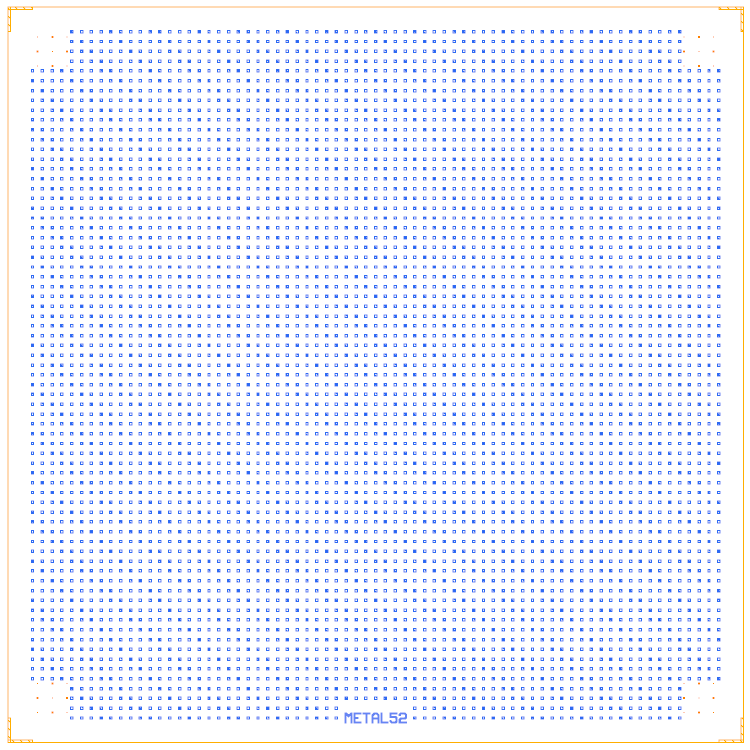

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m52_barends_5q_s1_die.png')

In [5]:
d = Designer("m52_barends_5q", box=(0, 0, 7500, 7500),
             chip={"name_chip": "Metal52", "cheese": metal_cheese_rule()}, live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
layout_step(d, OUT / "m52_barends_5q_s1_die.png", size=(750, 750), width=375)

## Design 2 · Bond pads: the PDK pad rule

The source puts three `LaunchpadWirebond`s on each edge, 2.8 mm from the centre, at −1.5, 0 and +1.5 mm along the
edge: W1–W3 (Q0's Z and XY lines, the feedline input), S1–S3, E1–E3 and N1–N3 (the other control lines and the
feedline output). In the Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from
the die edge**, whatever the source did: `edge="w"` / `"s"` / `"e"` / `"n"` slides each pad perpendicular to its
edge until it is there; its position along the edge is kept, so every line still arrives on the pad's axis and only
its last straight gets longer. The table measures it on the built layout; the picture zooms on `LP_W2` at the west edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_W1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_W2 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_W3 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_E1 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_E2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_E3 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_S1 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP_S2 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP_S3 | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| LP_N1 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| LP_N2 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| LP_N3 | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |

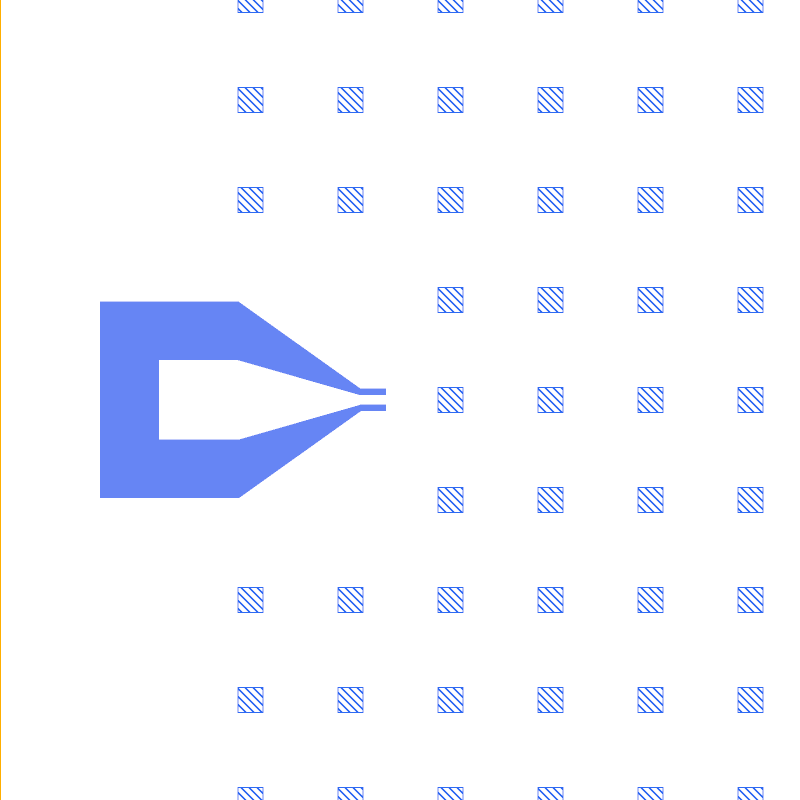

**On the chip so far:** 12 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 12 component(s) `LP_W1`, `LP_W2`, `LP_W3`, `LP_E1`, `LP_E2`, `LP_E3`, `LP_S1`, `LP_S2` … (+4).

WindowsPath('examples/designs/metal/m52_barends_5q_s2_pads.png')

In [6]:
SIDES = {"W": (-2800, None, 0, "w"), "E": (2800, None, 180, "e"), "S": (None, -2800, 90, "s"),
         "N": (None, 2800, 270, "n")}
lp = {}
with d.batch():
    for side, (x, y, r, edge) in SIDES.items():
        for k, c in enumerate((-1500, 0, 1500), 1):
            lp[f"{side}{k}"] = d.add(f"LP_{side}{k}", "metal:LaunchpadWirebond",
                                     at=P(x if x is not None else c, y if y is not None else c), rot=r, edge=edge)
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "LP_W2.tie")
layout_step(d, OUT / "m52_barends_5q_s2_pads.png", box=(0, py - 400, 800, py + 400), size=(800, 800), width=300)

## Design 3 · Readout: the tees, the Purcell capacitors and the feedline

The readout line needs no qubit, so it comes first. **Tees and Purcell capacitors.** The five `metal:CoupledLineTee`s (200 µm coupled arm, 4 µm space,
`open_termination=False`: the arm's far end is shorted, so the resonator from `second_end` is a λ/4 shorted at the
tee) sit on the feedline at y = +1.5 mm; the two `metal:CapNInterdigital` series capacitors bound the Purcell section.

- **Feedline:** launchpad W3 → `Cap_input` → the five tees (the Purcell section between the capacitors) →
  `Cap_output` → launchpad N1. The two long legs follow Metal's `RouteAnchors` corner points (fillets 100 / 20 µm).

CLT0 ports: ['prime_end', 'prime_start', 'second_end'] | Cap_input: ['north_end', 'south_end']


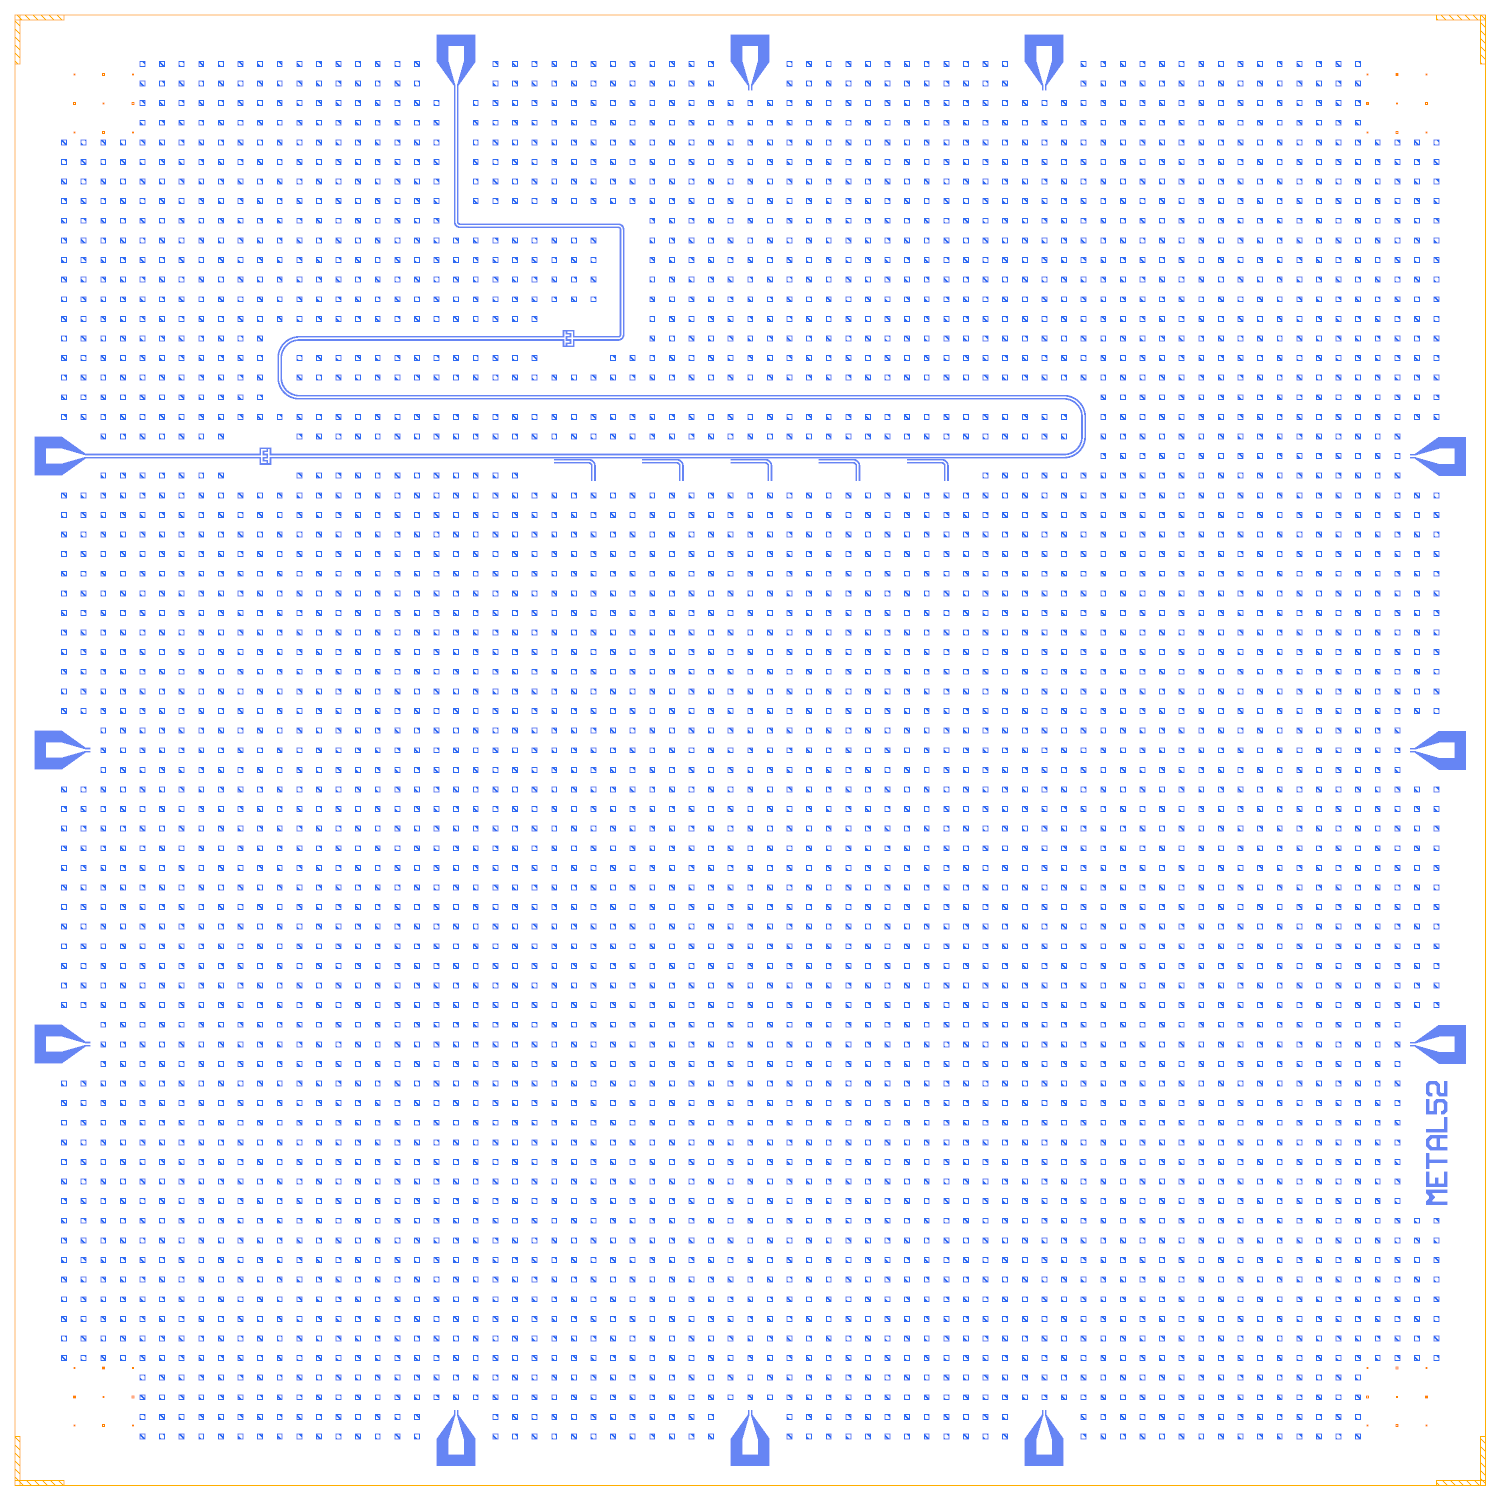

**On the chip so far:** 12 pads · 0 qubits · 7 other components · 8 routes · 0 declared couplings. **This step added** 7 component(s) `CLT0`, `CLT1`, `CLT2`, `CLT3`, `CLT4`, `Cap_input`, `Cap_output` and 8 route(s) `Feed_in_lp`, `Feed_in_clt`, `Feed_mid_0`, `Feed_mid_1`, `Feed_mid_2`, `Feed_mid_3`, `Feed_out_clt`, `Feed_out_lp`.

WindowsPath('examples/designs/metal/m52_barends_5q_s3_readout_line.png')

In [7]:
XS = [(i - 2) * PITCH for i in range(5)]
with d.batch():
    clt = [d.add(f"CLT{i}", "metal:CoupledLineTee", at=P(x, 1500), coupling_length=200, coupling_space=4,
                 open_termination=False) for i, x in enumerate(XS)]
    cap_in = d.add("Cap_input", "metal:CapNInterdigital", at=P(-2400, 1500), rot=270)
    cap_out = d.add("Cap_output", "metal:CapNInterdigital", at=P(-1000, 2100), rot=90)
    # feedline: launchpad → series cap → five tees (the Purcell section) → series cap → launchpad
    d.route("Feed_in_lp", lp["W3"].tie, cap_in.south_end, r=R)
    d.route("Feed_in_clt", cap_in.north_end, clt[0].prime_start, r=R)
    for i in range(4):
        d.route(f"Feed_mid_{i}", clt[i].prime_end, clt[i + 1].prime_start, r=R)
    d.route("Feed_out_clt", clt[4].prime_end, cap_out.north_end, r=100,
            nodes=PP([(1700, 1500), (1700, 1800), (-2400, 1800), (-2400, 2100)]))
    d.route("Feed_out_lp", cap_out.south_end, lp["N1"].tie, r=R, nodes=PP([(-654, 2100), (-654, 2675), (-1500, 2675)]))
print("CLT0 ports:", sorted(clt[0].ports), "| Cap_input:", sorted(cap_in.ports))
layout_step(d, OUT / "m52_barends_5q_s3_readout_line.png", size=(1500, 1500), width=520)

## Design 4 · Qubit placement: five Xmons at 450 µm pitch

**The qubits.** `metal:TransmonCrossFL` is Metal's Xmon with a flux line: a cross of 30 µm wide, 190 µm long arms in
a 50 µm gap, a `readout` claw on its north arm (`claw_length` 40 µm, well short of the 190 µm arm, so the DRC's
`pdk_claw` check is satisfied) and a flux T-line (`fl_options`) at its south arm. The source gives no junction and no
target frequency, so each qubit gets the **PDK SQUID**: `trilayer_junction(..., squid=True)` returns two trilayer
junctions (fingers on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient) whose parallel R_n is the PDK nominal
45 kΩ, so L_J = 6.73 nH at zero flux and C_J = 15 fF. The five qubits stay identical, as in the source.

They sit on the chip's axis at 450 µm pitch (`XS`), close enough that their ground pockets merge. The second picture
zooms on the chain with its tees above.

SQUID: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q0 ports: ['flux_line', 'readout', 'squid_a', 'squid_b']


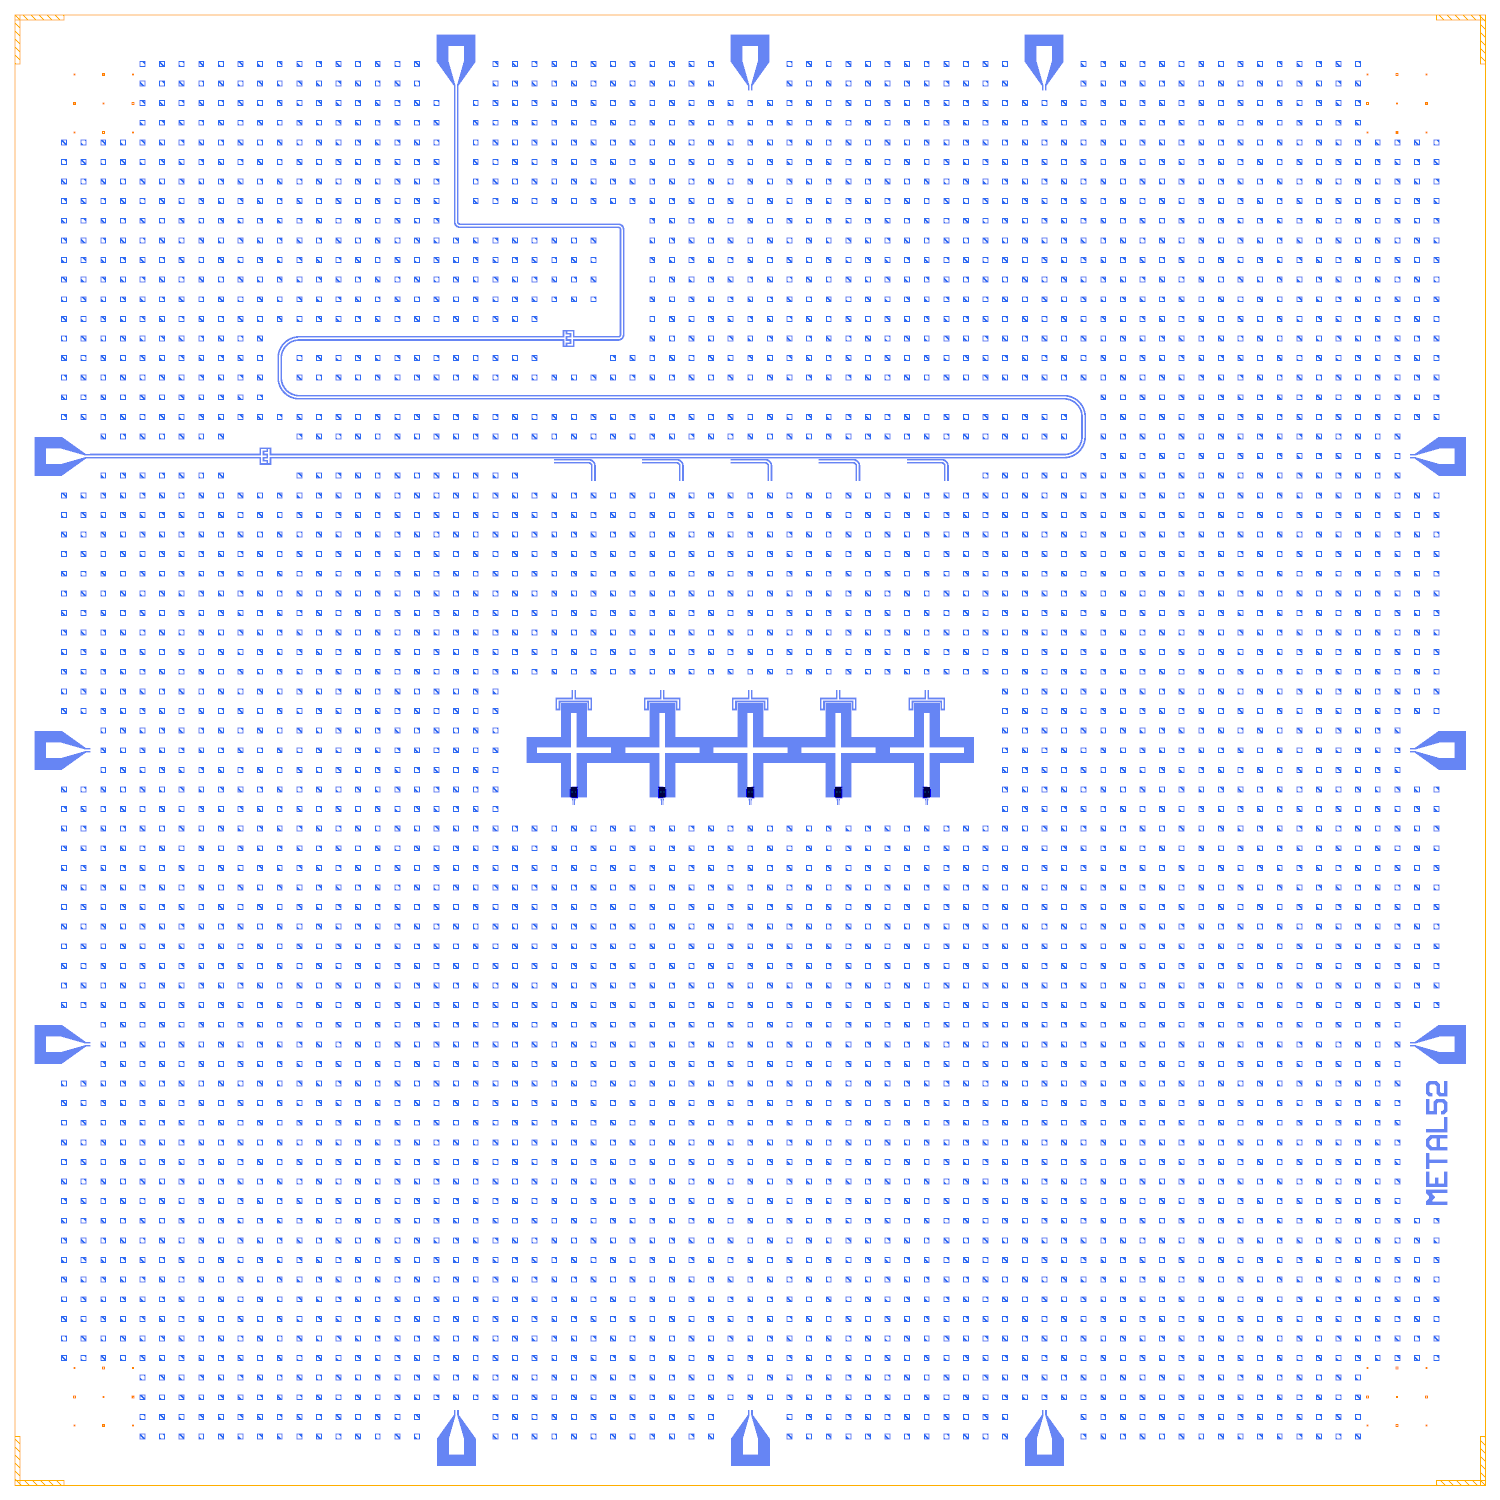

**On the chip so far:** 12 pads · 5 qubits · 7 other components · 8 routes · 0 declared couplings. **This step added** 5 component(s) `Q0`, `Q1`, `Q2`, `Q3`, `Q4`.

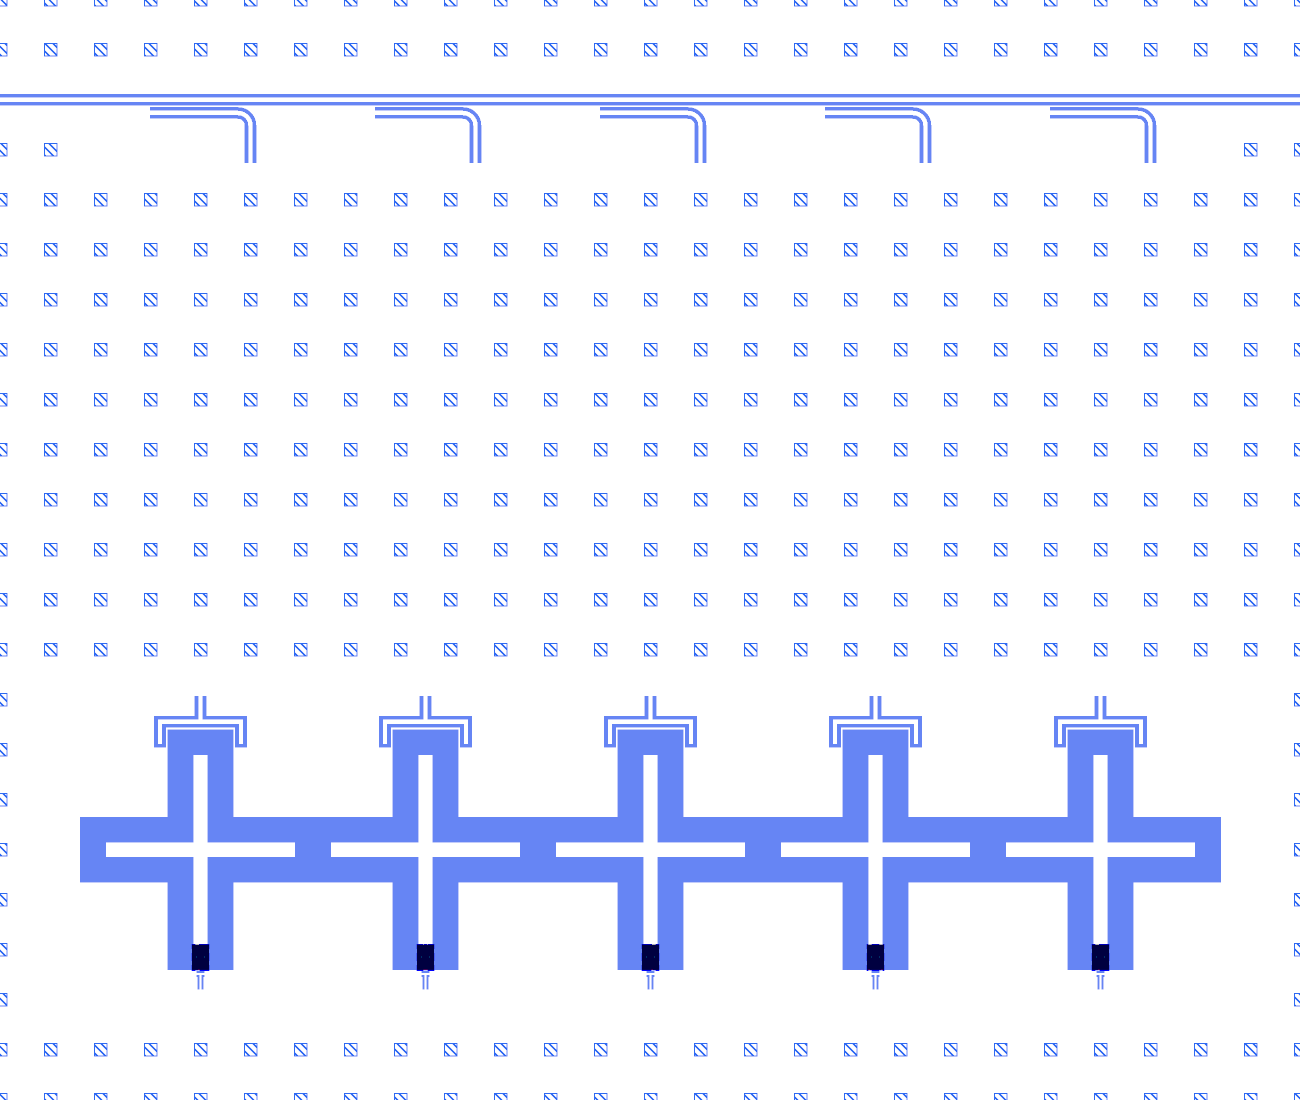

WindowsPath('examples/designs/metal/m52_barends_5q_step_parts.png')

In [8]:
_, JUNCTION = trilayer_junction("metal:TransmonPocket")                    # PDK nominal: R_n 45 kΩ, L_J 6.73 nH
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)  # 45 kΩ in parallel
print("SQUID:", SQ_PARAMS, SQUID)
XMON = dict(cross_width=30, cross_length=190, cross_gap=50, make_fl=True,
            fl_options=dict(t_gap=3, t_inductive_gap=3, t_offset=0, t_top=15, t_width=5),
            connection_pads={"readout": dict(connector_type="0", claw_length=40, ground_spacing=5, claw_width=10,
                                             claw_gap=6, connector_location="90")})
with d.batch():
    q = [d.add(f"Q{i}", "metal:TransmonCrossFL", at=P(x, 0), junction=SQUID, **SQ_PARAMS, **XMON)
         for i, x in enumerate(XS)]
print("Q0 ports:", sorted(q[0].ports))
layout_step(d, OUT / "m52_barends_5q_s4_qubits.png", size=(1500, 1500), width=520)
snap(d, OUT / "m52_barends_5q_step_parts.png", box=P(-1300, -500) + P(1300, 1700), size=(1300, 1100), width=520)

## Design 5 · Readout: the five λ/4 meanders

- **Readouts:** each claw (open end) → its tee's coupled arm (shorted end) is a λ/4 resonator; `readout_path` lays
  Metal's meander rows as waypoints with the source's length (4410 … 4570 µm, staggered tones).

**Simplified:** the readout meanders are Metal's (150 µm lead, 14 runs at 50 µm spacing from y = 451 to 1101 µm,
fillet 20 µm) except the last 32 µm jog to the tee leg, which is shorter than two 20 µm fillets in the qcc router:
the last run ends at the leg instead, and the run half-width grows by ≈ 2 µm so that each resonator keeps Metal's
total length.

They are plain routes on those waypoints (no `meander` length to fix): `readout_path` solves the run half-width so
that the drawn, filleted path is the source's length. The lengths and the half-widths are printed in Design 8.

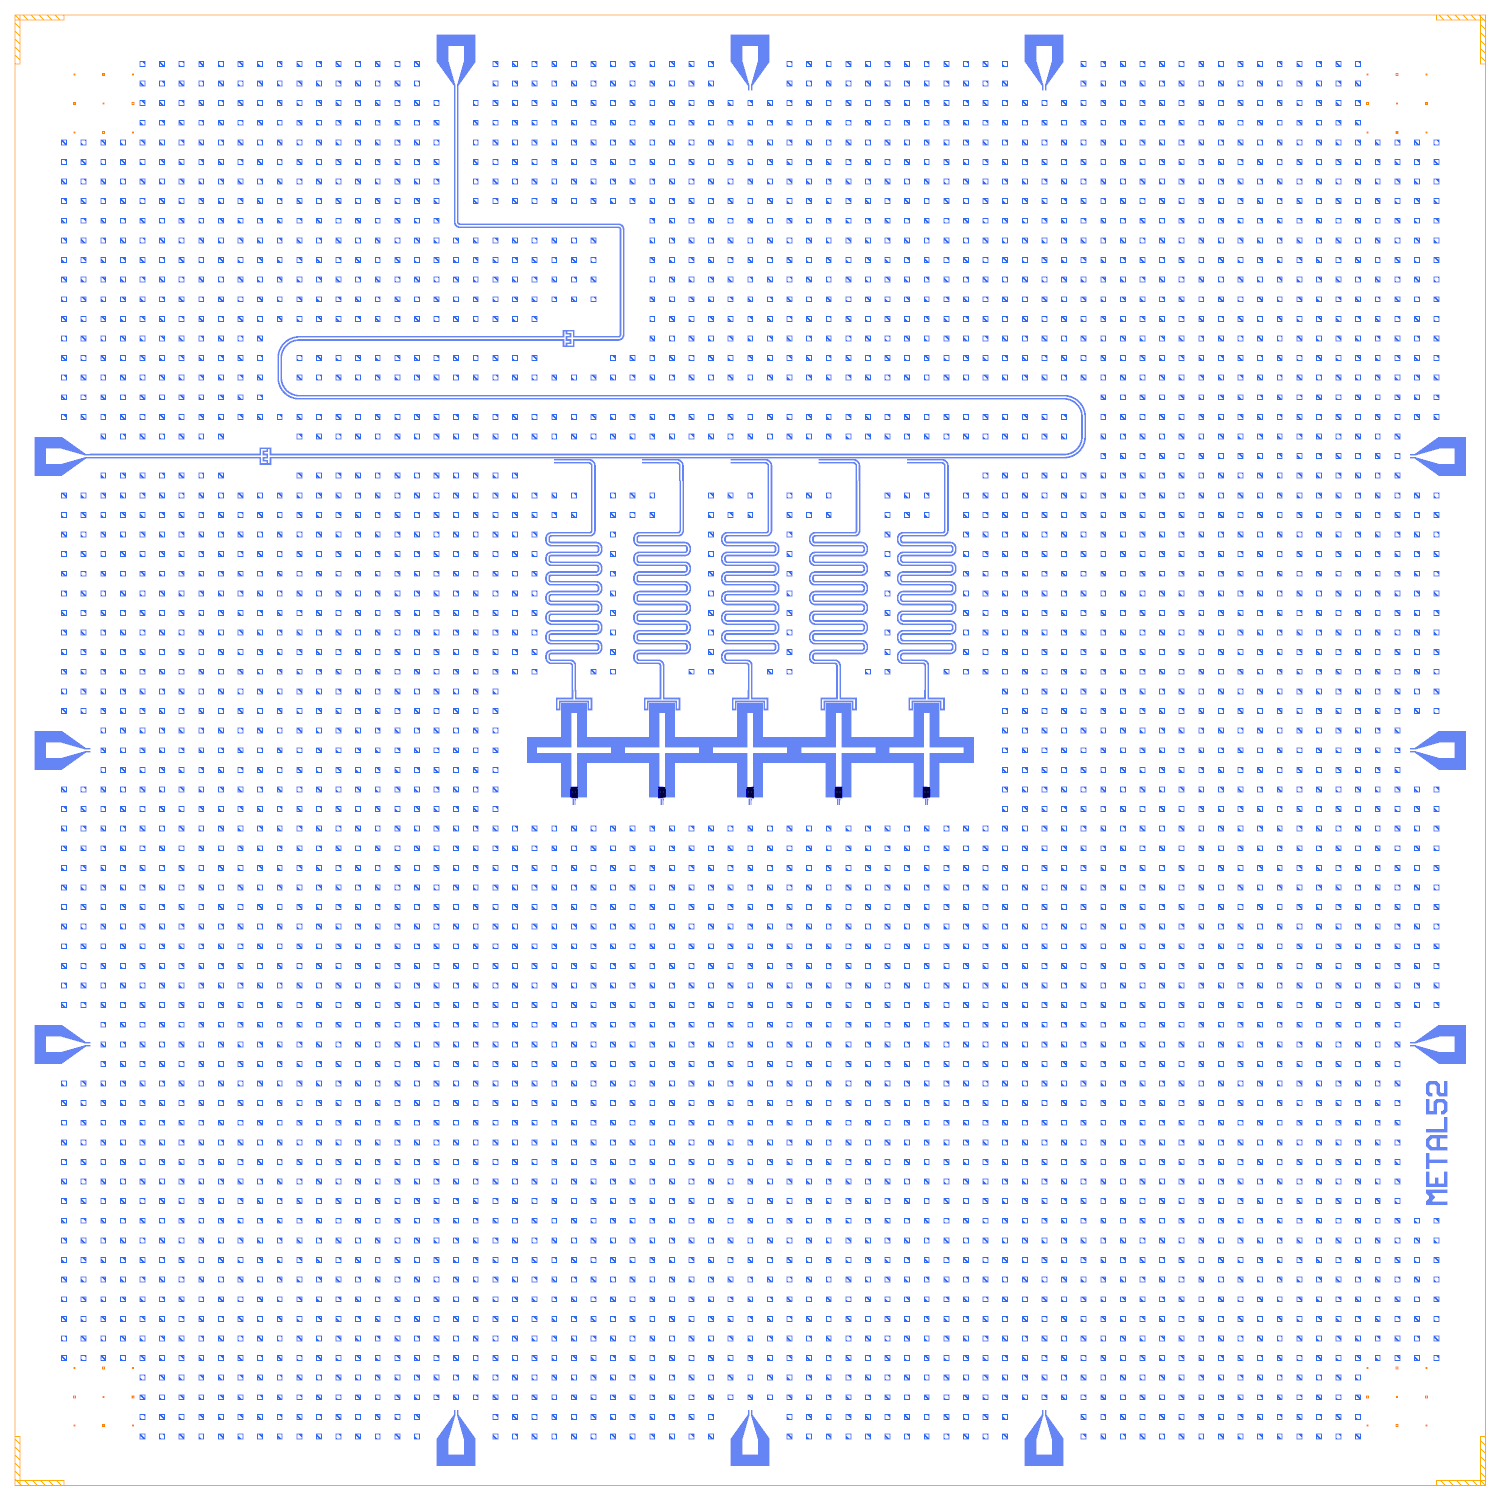

**On the chip so far:** 12 pads · 5 qubits · 7 other components · 13 routes · 0 declared couplings. **This step added** 5 route(s) `ReadoutRes0`, `ReadoutRes1`, `ReadoutRes2`, `ReadoutRes3`, `ReadoutRes4`.

WindowsPath('examples/designs/metal/m52_barends_5q_s5_readouts.png')

In [9]:
L_READ = [4410, 4450, 4490, 4530, 4570]          # Metal resonator_lengths (staggered tones)
half_widths = {}
with d.batch():
    # λ/4 readouts: claw (open) → tee leg (shorted), Metal's meander rows
    for i, x in enumerate(XS):
        pts, half_widths[f"ReadoutRes{i}"] = readout_path(x, L_READ[i])
        d.route(f"ReadoutRes{i}", q[i].readout, clt[i].second_end, r=R, nodes=PP(pts))
layout_step(d, OUT / "m52_barends_5q_s5_readouts.png", size=(1500, 1500), width=520)

## Design 6 · Coupling: the four direct neighbour couplings

There are no bus resonators: neighbouring cross arms face each other end-on across 70 µm (450 µm pitch − 2 × 190 µm
arms), and that is the coupling. No route carries it, so it is declared with `d.couple` (`Cg_Q0_Q1` … `Cg_Q3_Q4`) from
a coplanar-strip estimate (rough: it ignores the screening by the pocket ground beside the arms). The Q3D C-matrix job
`chain` replaces it. Nothing new is drawn, so the picture zooms on the chain.

C(Qi ↔ Qi+1) estimate: 3.08 fF (facing arms, 70 µm apart)


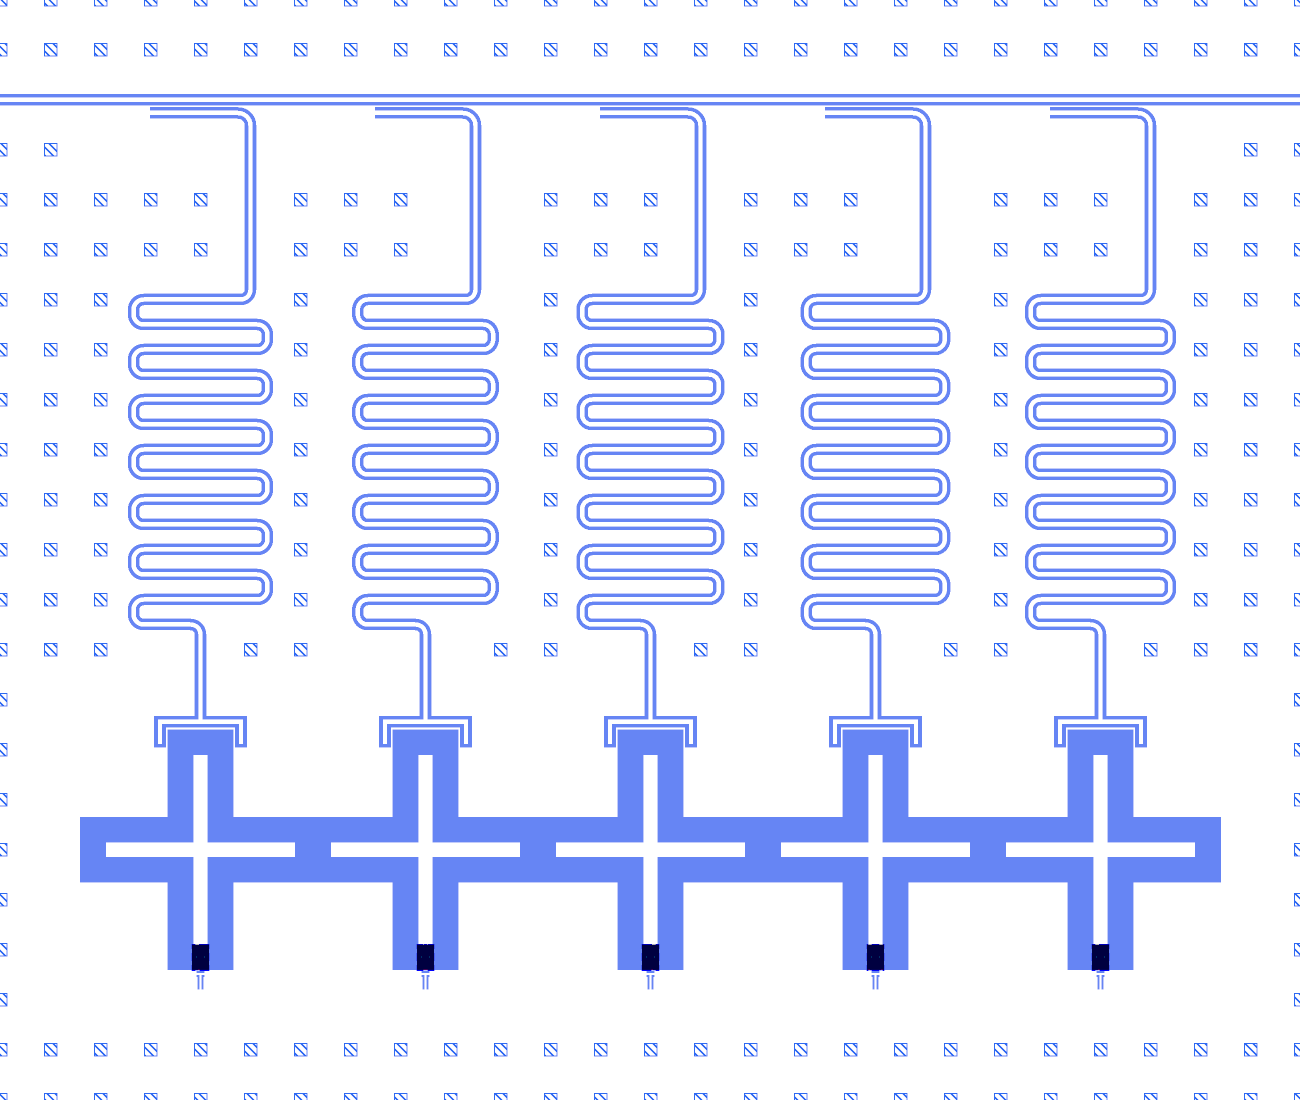

**On the chip so far:** 12 pads · 5 qubits · 7 other components · 13 routes · 4 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m52_barends_5q_s6_coupling.png')

In [10]:
C_QQ = round(est.coplanar_coupling(30, 190, 190, PITCH - 2 * 190, est.substrate_eps(get_pdk())), 2)
print("C(Qi ↔ Qi+1) estimate:", C_QQ, "fF (facing arms, 70 µm apart)")
with d.batch():
    for i in range(4):                           # the facing cross arms: no route carries them
        d.couple(f"Cg_Q{i}_Q{i + 1}", f"Q{i}", f"Q{i + 1}", C_fF=C_QQ, note="facing cross arms, 70 µm (CPS estimate)")
layout_step(d, OUT / "m52_barends_5q_s6_coupling.png", box=P(-1300, -500) + P(1300, 1700), size=(1300, 1100), width=520)

## Design 7 · Routing: the XY ends, the XY and Z lines

**XY ends.** Each drive line ends open at a `metal:OpenToGround` 100 µm left of its cross, 180 µm below its centre.

- **XY and Z lines:** Metal's `RouteFramed` corner points, 10/6 µm CPW, fillet 20 µm; each ends on its edge pad. Each Z line ends on its qubit's flux T-line (5/3 µm pin: the 10/6 µm line steps down to it), each XY line on
its open end; every line's last straight to its edge pad is longer by the pad move (Design 2).

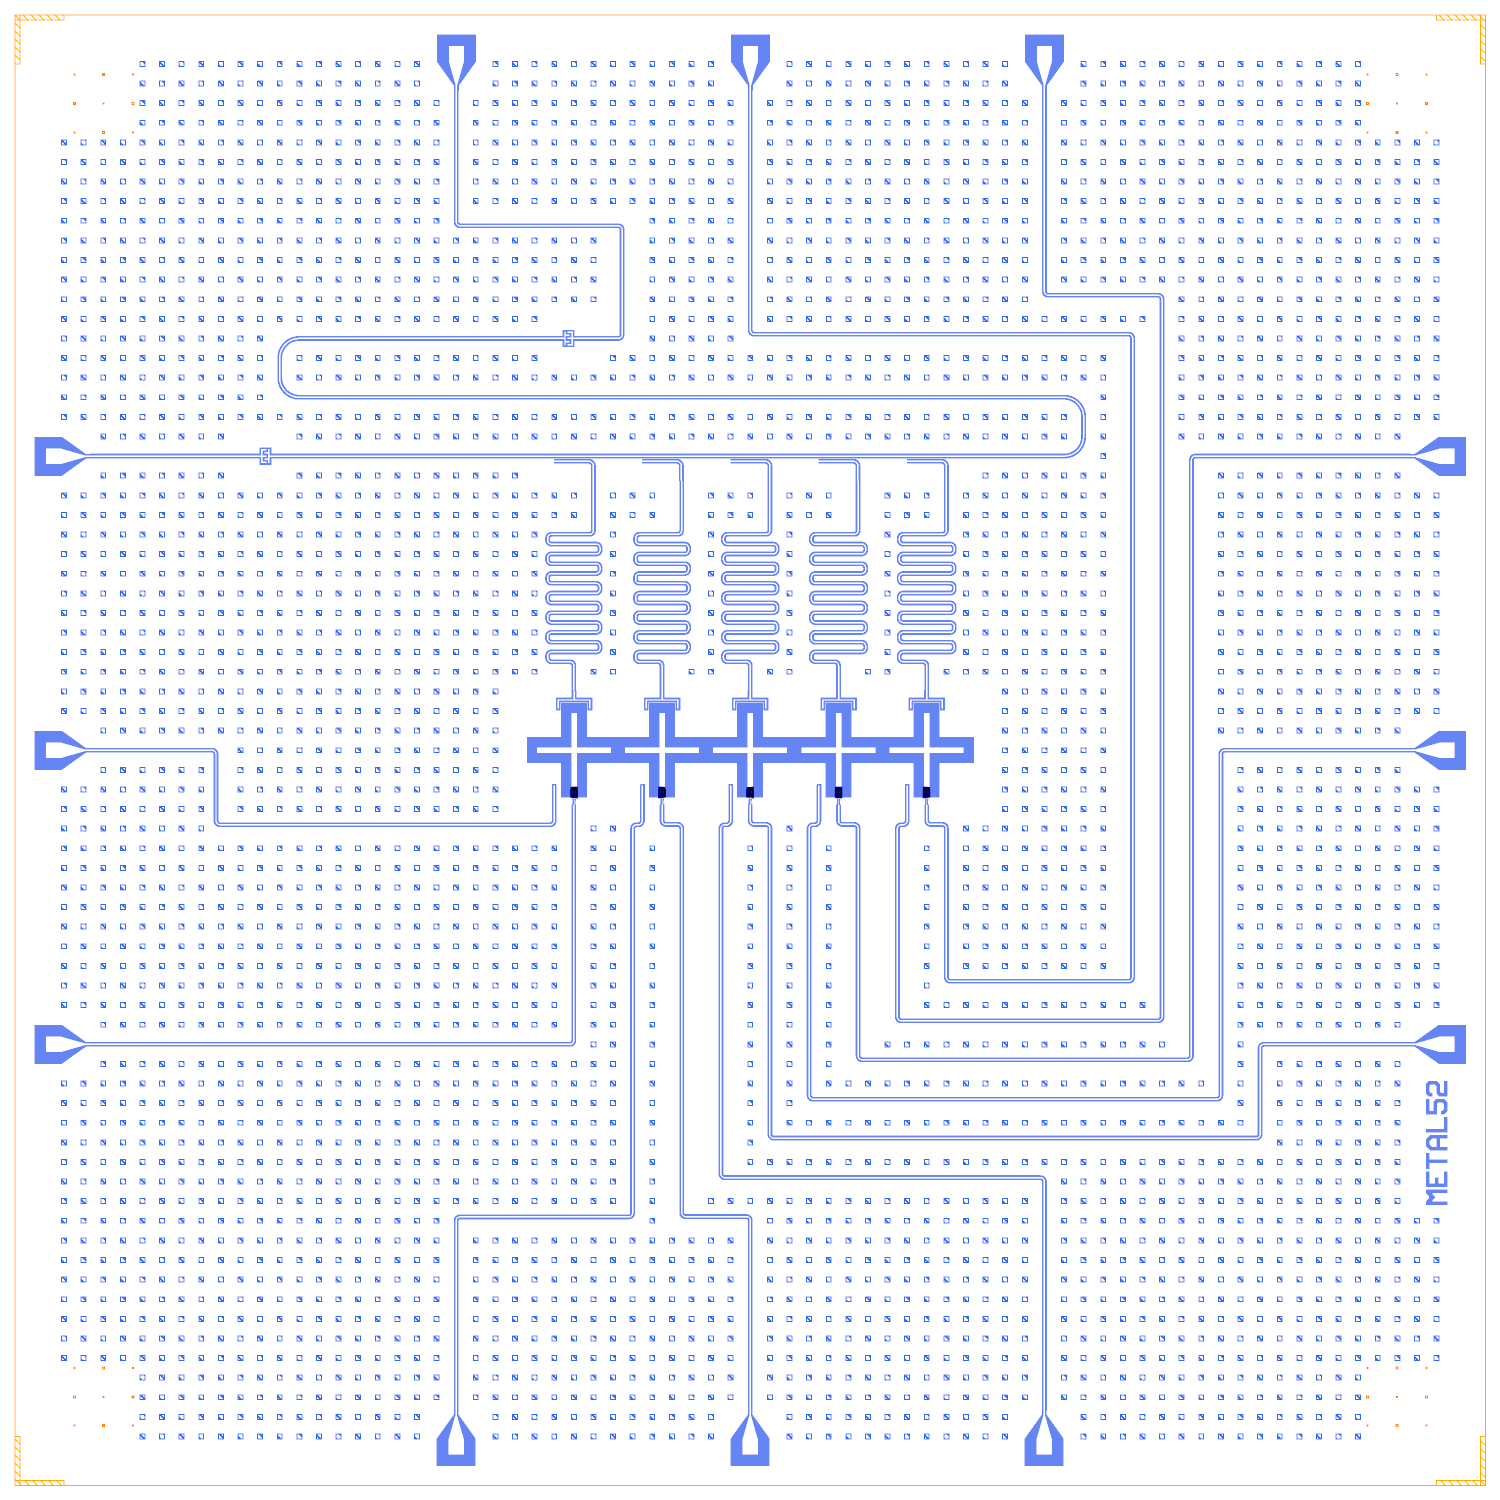

**On the chip so far:** 12 pads · 5 qubits · 12 other components · 23 routes · 4 declared couplings. **This step added** 5 component(s) `XY_pad_0`, `XY_pad_1`, `XY_pad_2`, `XY_pad_3`, `XY_pad_4` and 10 route(s) `XY_Line_0`, `Z_Line_0`, `XY_Line_1`, `Z_Line_1`, `XY_Line_2`, `Z_Line_2`, `XY_Line_3`, `Z_Line_3` … (+2).

WindowsPath('examples/designs/metal/m52_barends_5q_s7_control.png')

In [11]:
with d.batch():
    xy = [d.add(f"XY_pad_{i}", "metal:OpenToGround", at=P(x - 100, -180), rot=90, width=10, gap=6, termination_gap=6)
          for i, x in enumerate(XS)]

CTRL = {  # line: (start port, end pad, Metal's RouteFramed corner points)
    "XY_Line_0": (xy[0].open, lp["W2"].tie, [(-1000, -380), (-2725, -380), (-2725, 0)]),
    "Z_Line_0": (q[0].flux_line, lp["W1"].tie, [(-900, -1500)]),
    "XY_Line_1": (xy[1].open, lp["S1"].tie, [(-550, -380), (-600, -380), (-600, -2380), (-1500, -2380)]),
    "Z_Line_1": (q[1].flux_line, lp["S2"].tie, [(-450, -378.5), (-350, -378.5), (-350, -2378.5), (0, -2378.5)]),
    "XY_Line_2": (xy[2].open, lp["S3"].tie, [(-100, -380), (-150, -380), (-150, -2180), (1500, -2180)]),
    "Z_Line_2": (q[2].flux_line, lp["E1"].tie,
                 [(0, -378.5), (100, -378.5), (100, -1978.5), (2600, -1978.5), (2600, -1500)]),
    "XY_Line_3": (xy[3].open, lp["E2"].tie, [(350, -380), (300, -380), (300, -1780), (2400, -1780), (2400, 0)]),
    "Z_Line_3": (q[3].flux_line, lp["E3"].tie,
                 [(450, -378.5), (550, -378.5), (550, -1578.5), (2250, -1578.5), (2250, 1500)]),
    "XY_Line_4": (xy[4].open, lp["N3"].tie,
                  [(800, -380), (750, -380), (750, -1380), (2100, -1380), (2100, 2320), (1500, 2320)]),
    "Z_Line_4": (q[4].flux_line, lp["N2"].tie,
                 [(900, -378.5), (1000, -378.5), (1000, -1178.5), (1950, -1178.5), (1950, 2121.5), (0, 2121.5)]),
}
with d.batch():
    for name, (a, b, pts) in CTRL.items():       # XY (open drive ends) and Z (flux) lines
        d.route(name, a, b, r=R, a=10, b=6, nodes=PP(pts))
layout_step(d, OUT / "m52_barends_5q_s7_control.png", size=(1500, 1500), width=520)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: `chain` (a Q3D C-matrix of the five crosses with their XY
ends: the direct couplings and the drive capacitances) and `readout` (an eigenmode job: qubits, readouts, tees and the
Purcell section).

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it); it moves nothing when the content is within 50 µm of the centre. Here the twelve pads
sit on all four edges, so the content already spans the die and no shift is needed.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the tees, the feedline and the readouts were added before the XY / Z lines here),
so `git diff` stays empty.

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/metal/m52_barends_5q.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer m52_barends_5q: 29 instances, 23 routes, live=False> → examples\designs\metal\m52_barends_5q.json
route lengths (µm): {'Feed_in_lp': 819.0, 'Feed_in_clt': 1300.0, 'Feed_mid_0': 50.0, 'Feed_mid_1': 50.0, 'Feed_mid_2': 50.0, 'Feed_mid_3': 50.0, 'Feed_out_clt': 6528.3, 'Feed_out_lp': 2285.2, 'ReadoutRes0': 4410.0, 'ReadoutRes1': 4450.0, 'ReadoutRes2': 4490.0, 'ReadoutRes3': 4530.0, 'ReadoutRes4': 4570.0, 'XY_Line_0': 2919.2, 'Z_Line_0': 3677.9, 'XY_Line_1': 4100.7, 'Z_Line_1': 3502.2, 'XY_Line_2': 4850.7, 'Z_Line_2': 5500.6, 'XY_Line_3': 6452.1, 'Z_Line_3': 7250.6, 'XY_Line_4': 7893.5, 'Z_Line_4': 8392.0}
readout run half-widths (Metal 132 … 138 µm): {'ReadoutRes0': 133.74, 'ReadoutRes1': 135.28, 'ReadoutRes2': 136.82, 'ReadoutRes3': 138.36, 'ReadoutRes4': 139.9}


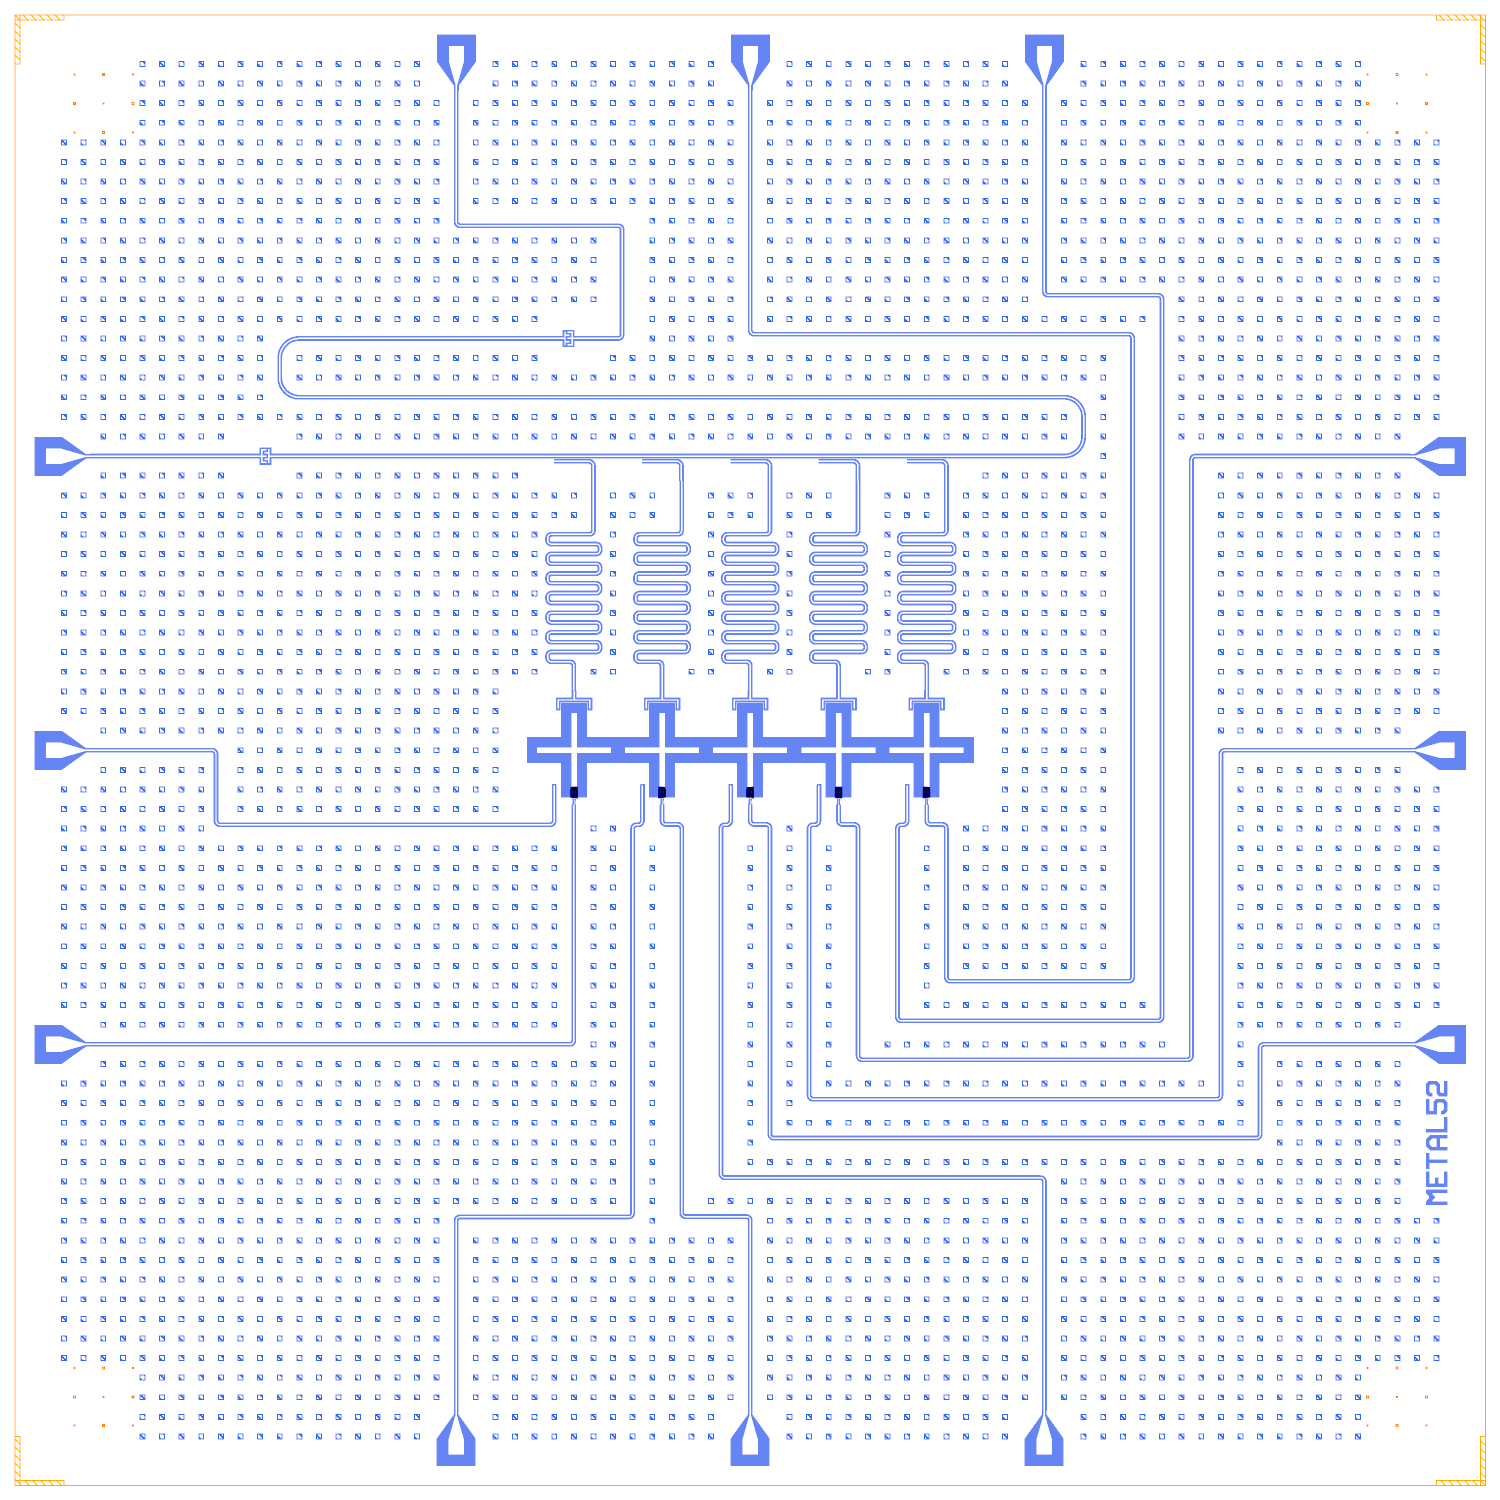

**On the chip so far:** 12 pads · 5 qubits · 12 other components · 23 routes · 4 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m52_barends_5q_step_routes.png')

In [12]:
d.sim_group("chain", [f"Q{i}" for i in range(5)] + [f"XY_pad_{i}" for i in range(5)], margin_um=30,
            analyses=["q3d_cmatrix"])
d.sim_group("readout", [f"Q{i}" for i in range(5)] + [f"ReadoutRes{i}" for i in range(5)] + [f"CLT{i}" for i in range(5)]
            + ["Cap_input", "Cap_output", "Feed_in_clt", "Feed_out_clt"] + [f"Feed_mid_{i}" for i in range(4)],
            margin_um=30, analyses=["eigenmode_epr"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "m52_barends_5q.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
print("readout run half-widths (Metal 132 … 138 µm):", {k: round(v, 2) for k, v in half_widths.items()})
layout_step(d, OUT / "m52_barends_5q_step_routes.png", size=(1500, 1500), width=520)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**; 10 `dangling_port` warnings (`squid_a` / `squid_b` of the five Xmons, the
junction attachment points: the cell draws the SQUID itself, nothing is routed there); 9 `overlap` warnings, by
design (neighbouring Xmon pockets merge at the 450 µm pitch, which is the direct coupling, and each XY
`OpenToGround` sits inside the bounding box of its cross, beside the lower-left arms); **no PDK design warnings**
(the twelve pads are at 100 µm, each PDK SQUID's parallel R_n is the nominal 45 kΩ, the 40 µm claws are short of the
190 µm arms, and the source has no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit:
- `TransmonCrossFL` → a grounded cross island with its SQUID, a node for the readout claw, the flux line as a
  control (the flux launchpads' ports drop out because the flux T-line shorts to ground);
- each readout claw → `CoupledLineTee` (shorted) is a λ/4 `TLres` (route + tee leg and coupler) with a hanger κ into
  the feedline;
- the four `Cg_Q*` capacitances are the neighbour couplings;
- the XY lines are 50 Ω drive ports ending open (the drive capacitance to the cross is geometric: it is in the
  `chain` C-matrix job).

**Not in the LOM:** the feedline is one node between the two series capacitors, so its ≈ 10 mm Purcell section
(λ/2 near the readouts) is not a resonator here; the eigenmode job `readout` contains it.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q2.", "CLT2."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat solves the circuit's normal modes (frequency, κ through the 50 Ω ports, anharmonicity); QuTiP diagonalises the
dressed Hamiltonian for f_q, α, f_r and χ. First each qubit with its readout and tee (the feedline is outside the
selection: with the whole feedline in, QuCat does not finish in reasonable time), then the five-qubit chain with
the four direct couplings. The source states no targets; the PDK band is 4–8 GHz.

What the tables show (from the v1 run):
- the five qubits at 6.35–6.36 GHz, α −266 … −277 MHz (Q4 −212 MHz: its readout sits closest), right on top of the
  λ/4 readouts at 6.09–6.27 GHz (staggered by ≈ 47 MHz, as the source intends): with the PDK SQUIDs at zero flux the
  qubits and readouts collide, so χ is large and of either sign (Q4 −31 MHz, the others +23 … +30 MHz). The source's
  frequency plan needs the Z lines (or another junction, LOM 3) to detune them; this is flagged, not retuned;
- **κ is 0 here, not a result:** the tee's feed side is the lumped feedline node of Check 2, which has no load when
  the feedline is outside the selection; the builder's hanger estimate into a matched line is in the netlist
  (`K_CLT*`), and the Purcell filter's effect needs the eigenmode job;
- the qubits are identical, so the chain's five modes are delocalised (hybridised, 6.19–6.58 GHz) and a per-pair ZZ
  is not defined ("–" in the ZZ table). Their spread comes from the coplanar-strip arm-to-arm estimate, which ignores
  the screening by the pocket ground beside the arms (an upper estimate; the Q3D `chain` job gives the real value).

In [ ]:
READ = {f"Q{i}+R{i}": [f"Q{i}", f"ReadoutRes{i}", f"CLT{i}"] for i in range(5)}
results = simulate_groups(d, READ)
display(Markdown(groups_md(results)))
chain = simulate_groups(d, {"chain": [f"Q{i}" for i in range(5)]}, max_modes=5)
display(Markdown("**Q0–Q4 chain, QuCat normal modes:**\n\n" + modes_md(chain["chain"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(chain)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. In the LOM each
readout is labelled by its tee (`CLT0` … `CLT4`: the λ/4 is the route plus the tee's coupled arm). From the v1 run
the plot shows the collision of LOM 1: every qubit marker (6.35 GHz) sits 0.1–0.3 GHz above its readout.

In [ ]:
plot_lom({**results, **chain}, OUT / "m52_barends_5q_lom.png", title="m52: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property, rebuild, re-run the LOM and compare. Here Q2's SQUID goes from the PDK nominal (L_J 6.73 nH, R_n 45 kΩ) to the top of
the PDK window (R_n ≈ 50 kΩ, L_J 7.32 nH as drawn): the most the PDK allows to move a qubit down without leaving the
R_n window. From the v1 run, f_q drops by ≈ 240 MHz (6.35 → 6.11 GHz), below its readout (6.20 GHz), so χ changes sign
(+24 → −14 MHz) and |α| comes down as the qubit–readout hybridisation changes. Detuning all five well below their
readouts needs the Z lines, as in the source.

In [ ]:
pdk_j = get_pdk().junction
LJ_50K = round(SQUID["Lj_nH"] * pdk_j.rn_target_kohm[1] / pdk_j.rn_nominal_kohm, 2)   # L_J ∝ R_n: R_n 50 kΩ
SQ50_PARAMS, SQUID_50K = trilayer_junction("metal:TransmonCrossFL", lj_nH=LJ_50K, squid=True)
print(f"Q2 SQUID: L_J {SQUID['Lj_nH']} → {SQUID_50K['Lj_nH']} nH (R_n 45 → ≈ 50 kΩ, the top of the PDK window)")
d2 = design_copy(DESIGN)
d2["Q2"].set(junction=SQUID_50K, **SQ50_PARAMS)
display(Markdown(params_delta_md({"Q2+R2": results["Q2+R2"]}, simulate_groups(d2, {"Q2+R2": READ["Q2+R2"]}))))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs: a **Q3D C-matrix** for the qubit chain with the XY ends (the direct couplings and the drive capacitances;
the box cuts each readout, XY and Z line once: they become ports), and an **eigenmode / EPR** job for the qubits,
readouts, tees and the Purcell section (lines leaving the box end in 50 Ω, so the mode Q gives κ through the filter;
`Z_Line_4` passes through the box top).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["chain"])
jobs_eig = export_sims(DESIGN, ["readout"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the chain: the five cross islands, their readout claws and the five XY ends, with the lines the box
cuts as nets. It replaces the assumed arm-to-arm `Cg_Q*` and gives the XY drive capacitances. Each net is named after
its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves the job with `RUN_FEM`,
else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `readout` box in HFSS eigenmode: the five SQUIDs are lumped L_J ‖ C_J sheets, the readouts, tees and the Purcell
section between the two capacitors are inside, and the lines leaving the box end in 50 Ω, so each readout mode's Q gives
κ through the Purcell filter (the LOM has κ = 0 here, LOM 1). pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns each junction's energy participation into the dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box: here the feedline's S21 through the Purcell section, with
one notch per readout. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option
yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh
seeds, the adaptive-mesh frequency at the eigenmode's highest readout mode (the LOM's `CLT0` f_r before the eigenmode
is solved) and a fast sweep from 0.4 GHz below it to 0.2 GHz above, which holds all five readouts (6.09–6.27 GHz in
the v1 LOM run).

In [ ]:
f_r0 = results["Q0+R0"].params.get("CLT0.f_GHz")            # the LOM's highest readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "readout", jobs_eig["readout"][0], keep_eig["readout"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["readout"]:
    display(Markdown(driven_md(keep_drv["readout"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the participation p_J of the first junction, with the LOM's qubit and readout frequencies as dashed
lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {}
for i in range(5):
    p = results[f"Q{i}+R{i}"].params
    lom_f[f"Q{i}"], lom_f[f"CLT{i}"] = p.get(f"Q{i}.f_q_GHz"), p.get(f"CLT{i}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "m52_barends_5q_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: each qubit's mode is the one its own junction participates in most, each
readout's the remaining mode nearest the LOM's f_r (in order); f_q and f_r are pyEPR's dressed frequencies, α and χ
its Kerr terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds the S21 notches
(the one nearest each LOM f_r).

In [ ]:
fem_values = {}
if keep_eig.get("readout"):
    fem_values = epr_values(keep_eig["readout"], {f"Q{i}": f"CLT{i}" for i in range(5)},
                            {f"CLT{i}": lom_f[f"CLT{i}"] for i in range(5)})
if keep_drv["readout"]:
    for i in range(5):
        fem_values.update({f"driven {k}": v for k, v in
                           driven_values(keep_drv["readout"], f"CLT{i}", lom_f[f"CLT{i}"]).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for k, v in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of the five qubits "
          "and readouts from pyEPR, and the S21 notches of the feedline.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of each qubit with its
readout and tee (LOM 1's groups) by the `chain` job's C-matrix values (matched by net name; the readout lines keep their
estimates) and the same LOM runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is
the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for i in range(5):
    g, lom_p = f"Q{i}+R{i}", results[f"Q{i}+R{i}"].params
    keys = [f"Q{i}.f_q_GHz", f"Q{i}.alpha_MHz", f"CLT{i}.f_GHz", f"CLT{i}.chi_MHz", f"CLT{i}.kappa_MHz"]
    if keep_q3d.get("chain"):
        on_fem = simulate(fill(d.lom(select=READ[g]).model, DESIGN, keep_q3d["chain"]), max_modes=2).params
        rows += [(key, lom_p.get(key), on_fem.get(key), "LOM on the chain C-matrix") for key in keys]
    rows += [(key, lom_p.get(key), fem_values[key], "eigenmode + pyEPR") for key in keys if key in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the chain's Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no targets; with the PDK SQUIDs at zero flux every qubit sits on top of its readout (from the v1
run: `Q2` at 6.35 GHz, its readout `CLT2` at 6.18 GHz), where χ is large and of either sign. This notebook sets one
target as an exercise that moves a qubit off its readout: **Q2 at 6.60 GHz**, ≈ 0.4 GHz above its readout. It is
reachable inside the PDK junction window: by the transmon formula (E_C ≈ |α| ≈ 0.27 GHz from the v1 run) Q2's SQUID goes
from L_J 6.73 nH to ≈ 6.25 nH, R_n ≈ 42 kΩ in parallel (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ). Moving
it *below* the readout instead is limited by the window: LOM 3 shows its top (50 kΩ) gives only 6.11 GHz.

The target goes on a copy (`target_copy` → `build/m52_barends_5q_target.json`), so the design file keeps its own
(none). `loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — five here, minutes — on the Q3D values where a solve was kept, and picks one value per quantity (the
consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its
tolerance (f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the
LOM's L_J (`Q2.junction.Lj_nH`); to draw the new SQUID set both with
`trilayer_junction("metal:TransmonCrossFL", lj_nH=..., squid=True)`. Near the qubit–readout crossing the dressed
states mix: if the consensus spread is large, the estimators disagree about which mode is the qubit.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q2": {"f_q_GHz": 6.60}}              # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until the
target is inside its tolerance or `MAX_ITER` revisions are made (`build/m52_barends_5q/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's `chain` Q3D job is exported and solved first
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value
against the target and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's chain Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = export_sims(rev, ["chain"], root=f"build/jobs/rev{k}")
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "m52_barends_5q_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** Example 52 ends by exporting its chip with Metal's `QGDSRenderer`
(`gds_renderer.export_to_gds(...)`; "the renderer logs notes on cheesing"), with the cheese at its defaults: on for
the main layer (`cheese.view_in_file = {main: {1: True}}`), `cheese_0_x/y` 25 µm squares every `delta_x/y` 100 µm,
none within `edge_nocheese` 200 µm of the chip edge and `no_cheese.buffer` 25 µm clear of every etched shape. So the
original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule
as its `cheese` parameter (Design 1: `metal_cheese_rule()` = `{size, gap, rows, clearance, edge}`), so the build draws
it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0
keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few
µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask`
keep it (`cheese source: build`, no PDK band added). (Before 2026-11-04 the cheese was drawn but KQC's layer
properties hid `ground grid` 132/1, the "no cheese in Barends 52" seen in KLayout; snapshots now use
`live.snapshot.layer_props_path()`, which shows it. Load that file in KLayout, File → Load Layer Properties, to see
it in the GUI.)

Command-line equivalents:
- `qcc build examples/designs/metal/m52_barends_5q.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/m52_barends_5q.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/m52_barends_5q.json -g chain -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the source's last figure: the same components, pins and route paths, the pads now at the die
edge, Metal's cheese over the free ground); the five Xmons with their merged pockets; Q2's cross with its readout
claw, XY end and flux T-line; Q2's trilayer SQUID; the Q0 tee on the feedline; the **fab mask** round Q2 (1/0 etch
with the Metal cheese, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on
1000/0, alignment grid on 1001/0). Positions are read from the design.

In [ ]:
QX, QY = d.data["instances"]["Q2"]["place"]["at"]
TX, TY = d.data["instances"]["CLT0"]["place"]["at"]
show_snapshot(d, OUT / "m52_barends_5q.png", size=(1500, 1500))
show_snapshot(d, OUT / "m52_barends_5q_chain.png", box=(QX - 1200, QY - 450, QX + 1200, QY + 450), size=(1600, 600),
              width=640)
show_snapshot(d, OUT / "m52_barends_5q_q2.png", box=(QX - 280, QY - 320, QX + 280, QY + 340), width=400)
show_snapshot(d, OUT / "m52_barends_5q_jj.png", box=(QX - 40, QY - 250, QX + 40, QY - 170), size=(800, 800),
              width=300)
show_snapshot(d, OUT / "m52_barends_5q_tee.png", box=(TX - 250, TY - 200, TX + 300, TY + 60), size=(1100, 520),
              width=440)
snap_file(Path("build") / "m52_barends_5q_fab.oas", OUT / "m52_barends_5q_cheese.png",
          box=(QX - 900, QY - 600, QX + 900, QY + 1200), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "m52_barends_5q_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins, the feedline and the ten XY / Z control-line paths (Metal's corner points), the readout lengths (4410 … 4570 µm), the sim groups; Metal's GDS cheese (25 µm / 100 µm, 25 µm buffer), drawn by the build and kept in the mask |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame; sapphire stack; the twelve launchpads 100 µm from the edges (were ≈ 650 µm in); PDK trilayer SQUIDs (45 kΩ in parallel, L_J 6.73 nH); content centred (no shift needed) |
| differs | the readout's last jog (the run half-width grows by ≈ 2 µm to keep the length); the qubits at 6.35 GHz (from the v1 run) sit on their readouts with the PDK SQUIDs at zero flux (LOM 1) |
| PDK design warnings | none |
| layout | built in segments (die, pads, the tees with the Purcell capacitors and the feedline, the Xmons, the readouts, the declared couplings, the XY / Z lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q2 6.60 GHz, off its readout): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`); κ needs the feedline in the LOM (or the eigenmode job); the arm-to-arm coupling is an estimate until the `chain` Q3D job is solved |